In [1]:
import numpy as np
import xarray as xr
import xrft
# from scipy.fft import fft, ifft
import matplotlib.pyplot as plt


## Define parameters

In [2]:
working_dir = "/scratch/tmp/"  # Define your working directory

# Setting parameters
c = 299792458.0
PRF = 1857
f0 = 1275e6
d_az = 3.74
v = PRF * d_az
t0 = 1000e3 * 2 / c
d_rt = 3.33333333334e-08
z0 = t0 * c / 2

## Read slc

In [3]:
in_path = 's3://bopen-sar/ARD-ROSE-L/SAOCOM/Naples/ASC/S4/slcs.zarr/'
slc_stack = xr.open_datatree(in_path, engine='zarr', chunks={}, consolidated=True)
slc = slc_stack.orig['2020-04-23T04:51:27.189461'].to_dataset().slc.squeeze()

slc = slc.drop_vars(['azimuth_m', 'azimuth_time']).persist()

/tmp/ipykernel_14335/3501080490.py:2: FutureWarning: In a future version, xarray will not decode timedelta values based on the presence of a timedelta-like units attribute by default. Instead it will rely on the presence of a timedelta64 dtype attribute, which is now xarray's default way of encoding timedelta64 values. To continue decoding timedeltas based on the presence of a timedelta-like units attribute, users will need to explicitly opt-in by passing True or CFTimedeltaCoder(decode_via_units=True) to decode_timedelta. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  slc_stack = xr.open_datatree(in_path, engine='zarr', chunks={}, consolidated=True)


In [4]:
records, samples = slc.shape

# Preparing the axis for azimuth wavenumbers
kx = np.arange(records) - records // 2
kx = xr.DataArray(kx * (2 * np.pi * PRF / v / records), dims='freq_azimuth_time')

# Monochromatic approximation
w0 = 2 * np.pi * f0
kz0 = 2 * w0 / c


## Defocusing and burst extraction

In [5]:
# FFT to azimuth frequency (Doppler)
s__ = xrft.fft(slc.chunk(azimuth_time=-1), dim='azimuth_time', true_phase=True, true_amplitude=True)

t = xr.DataArray(t0 + np.arange(samples) * d_rt, dims='slant_range_time')

# De-focusing to orbit height
phase = ((c * t / 2) * np.sqrt(kx**2 + kz0**2)).T
phase = phase.chunk(s__.chunks).persist()

s__ = s__ * np.exp(-1j*phase)

# IFFT to azimuth time
s__ = xrft.ifft(s__, dim='freq_azimuth_time', true_phase=True, true_amplitude=True)

b1 = s__.copy()
b2 = s__.copy()

# Carving manually a burst in azimuth time
b1[:15000, :] = 0
b1[18000:, :] = 0

b2[:12000, :] = 0
b2[15000:, :] = 0

b1 = b1.persist()
b2 = b2.persist()


/tmp/ipykernel_14335/426783196.py:8: DeprecationWarning: Supplying chunks as dimension-order tuples is deprecated. It will raise an error in the future. Instead use a dict with dimension names as keys.
  phase = phase.chunk(s__.chunks).persist()
/home/fminati/anaconda3/envs/unwrap/lib/python3.11/site-packages/xrft/xrft.py:573: FutureWarning: Default ifft's behaviour (lag=None) changed! Default value of lag was zero (centered output coordinates) and is now set to transformed coordinate's attribute: 'direct_lag'.
  warnings.warn(msg, FutureWarning)


## Refocusing

In [6]:
# FFT to azimuth frequency
b1 = xrft.fft(b1, dim='azimuth_time', true_phase=True, true_amplitude=True)

# Re-focusing down to target
b1 = b1 * np.exp(1j*phase)

# IFFT to azimuth time
b1 = xrft.ifft(b1, dim='freq_azimuth_time', true_phase=True, true_amplitude=True).persist()

/home/fminati/anaconda3/envs/unwrap/lib/python3.11/site-packages/xrft/xrft.py:573: FutureWarning: Default ifft's behaviour (lag=None) changed! Default value of lag was zero (centered output coordinates) and is now set to transformed coordinate's attribute: 'direct_lag'.
  warnings.warn(msg, FutureWarning)


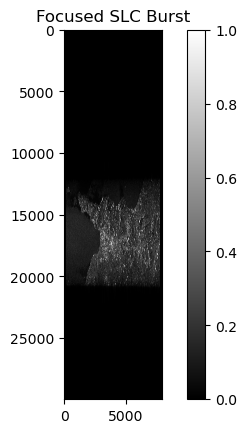

In [7]:

# Visualization (optional)
plt.figure()
plt.imshow(np.abs(b1), cmap='gray', vmin=0, vmax=1)
plt.title("Focused SLC Burst")
plt.colorbar()
plt.show()

In [8]:
# FFT to azimuth frequency
b2 = xrft.fft(b2, dim='azimuth_time', true_phase=True, true_amplitude=True)

# Re-focusing down to target
b2 = b2 * np.exp(1j*phase)

# IFFT to azimuth time
b2 = xrft.ifft(b2, dim='freq_azimuth_time', true_phase=True, true_amplitude=True).persist()

/home/fminati/anaconda3/envs/unwrap/lib/python3.11/site-packages/xrft/xrft.py:573: FutureWarning: Default ifft's behaviour (lag=None) changed! Default value of lag was zero (centered output coordinates) and is now set to transformed coordinate's attribute: 'direct_lag'.
  warnings.warn(msg, FutureWarning)


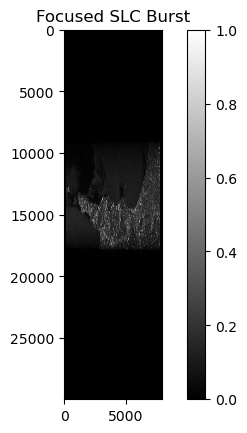

In [9]:

# Visualization (optional)
plt.figure()
plt.imshow(np.abs(b2), cmap='gray', vmin=0, vmax=1)
plt.title("Focused SLC Burst")
plt.colorbar()
plt.show()